# Task 1: Web Scraping

In [1]:
!pip install requests beautifulsoup4

In [2]:
import requests
from bs4 import BeautifulSoup

url = "https://books.toscrape.com/"
response = requests.get(url)
soup = BeautifulSoup(response.text,"html.parser")

books = soup.find_all("article", class_="product_pod")
print(len(books))

20


In [3]:
import pandas as pd

data = []
for book in books:
    title = book.h3.a["title"]
    price = book.find("p", class_="price_color").text
    rating = book.find("p", class_="star-rating")["class"][1]
    stock = book.find("p",class_="instock availability").text.strip()
    data.append({"Title": title, "Price": price, "Rating": rating, "Stock": stock})
df = pd.DataFrame(data)
df.head()

,Title,Price,Rating,Stock
0,A Light in the Attic,Â£51.77,Three,In stock
1,Tipping the Velvet,Â£53.74,One,In stock
2,Soumission,Â£50.10,One,In stock
3,Sharp Objects,Â£47.82,Four,In stock
4,Sapiens: A Brief History of Humankind,Â£54.23,Five,In stock


In [4]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

data = []
for page in range(1, 51):
    url = f"https://books.toscrape.com/catalogue/page-{page}.html"
    response = requests.get(url)
    response.encoding = "utf-8"
    soup = BeautifulSoup(response.text, "html.parser")
    for book in soup.find_all("article", class_="product_pod"):
        title = book.h3.a["title"]
        price = book.find("p", class_="price_color").text
        rating = book.find("p", class_="star-rating")["class"][1]
        stock = book.find("p", class_="instock availability").text.strip()
        data.append({"Title": title, "Price": price, "Rating": rating, "Stock": stock})

df = pd.DataFrame(data)
df.to_csv("books_data.csv", index=False, encoding="utf-8-sig")
print(len(df))
df.head()

1000


,Title,Price,Rating,Stock
0,A Light in the Attic,£51.77,Three,In stock
1,Tipping the Velvet,£53.74,One,In stock
2,Soumission,£50.10,One,In stock
3,Sharp Objects,£47.82,Four,In stock
4,Sapiens: A Brief History of Humankind,£54.23,Five,In stock


# Task 2: Exploratory Data Analysis (EDA)

In [5]:
import pandas as pd

df = pd.read_csv("books_data.csv")

# clean the price column: keep only digits and dot, then make it a number
df["Price"] = df["Price"].str.replace(r"[^0-9.]", "", regex=True).astype(float)

# Turn rating words into numbers
rating_map = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}
df["Rating"] = df["Rating"].map(rating_map)

print(df.info())
print(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Title   1000 non-null   str    
 1   Price   1000 non-null   float64
 2   Rating  1000 non-null   int64  
 3   Stock   1000 non-null   str    
dtypes: float64(1), int64(1), str(2)
memory usage: 77.4 KB
None
            Price       Rating
count  1000.00000  1000.000000
mean     35.07035     2.923000
std      14.44669     1.434967
min      10.00000     1.000000
25%      22.10750     2.000000
50%      35.98000     3.000000
75%      47.45750     4.000000
max      59.99000     5.000000


In [6]:
print(df["Rating"].value_counts().sort_index())
print()
print(df.groupby("Rating")["Price"].mean().round(2))
print()
print(df["Stock"].value_counts())
print()
print(df.nlargest(5, "Price")[["Title", "Price"]])

Rating
1    226
2    196
3    203
4    179
5    196
Name: count, dtype: int64

Rating
1    34.56
2    34.81
3    34.69
4    36.09
5    35.37
Name: Price, dtype: float64

Stock
In stock    1000
Name: count, dtype: int64

                                  Title  Price
648  The Perfect Play (Play by Play #1)  59.99
617   Last One Home (New Beginnings #1)  59.98
860    Civilization and Its Discontents  59.95
560      The Barefoot Contessa Cookbook  59.92
366           The Diary of a Young Girl  59.90


## EDA Findings

- Ratings are evenly spread, with 1-star the most common (226 books).
- Price does not predict rating: average price is about 35 pounds at every rating level.
- All 1000 books are "In stock",so that column adds no information.
- No outliers: prices run smoothly from 10 to 59.99 pounds.

# Task 3: Data Visualization

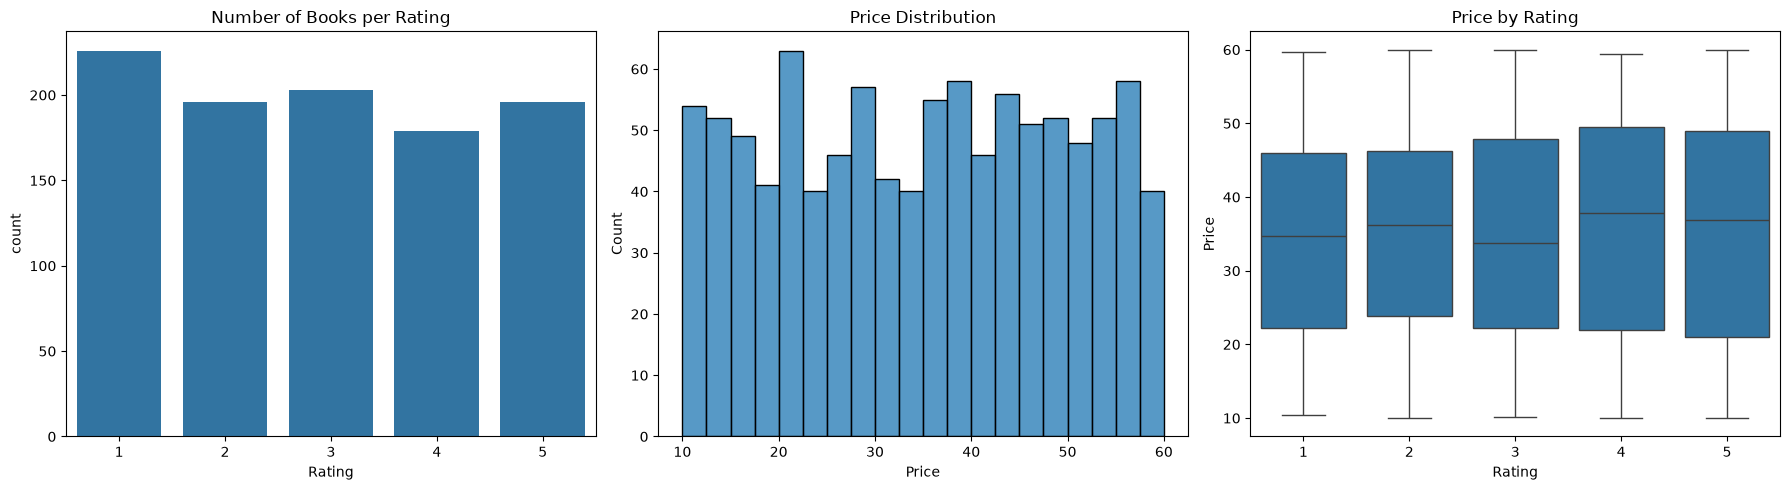

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.countplot(x="Rating", data=df, ax=axes[0])
axes[0].set_title("Number of Books per Rating")

sns.histplot(df["Price"], bins=20, ax=axes[1])
axes[1].set_title("Price Distribution")

sns.boxplot(x="Rating", y="Price", data=df, ax=axes[2])
axes[2].set_title("Price by Rating")

plt.tight_layout()
plt.savefig("book_charts.png")
plt.show()

- Books are spread evenly across the 5 ratings.
- Prices are spread evenly from about 10 pound to 60 pound,with no single price range dominating.
- The price boxes look almost identical at every rating, so rating doesn't depend on price.